# SEAQT quantum annealing evolution -- walkthrough

This notebook is a guided tour of everything in this repo: two
thermodynamically-consistent dissipative dynamics for quantum annealing
(SEAQT and bath relaxation), an ad hoc Hamiltonian and the real D-Wave QPU
Hamiltonian, 1 and 2 qubits, and a genuine numerical gotcha that shows up
once you go past 1 qubit.

**Physics recap**

Both dissipators are plugged into the same unitary backbone:

$$\dot\rho\big|_{\text{unitary}} = -\frac{i}{\hbar}[H(t), \rho]$$

1. **SEAQT** (Steepest-Entropy-Ascent Quantum Thermodynamics) -- an isolated
   system relaxing toward the max-entropy state at *fixed energy*:
   $$\dot\rho\big|_{\text{diss}} = \frac{1}{\tau} D(\rho, H), \qquad
     D(\rho,H) = \mathrm{proj}_{\perp\,\mathrm{span}\{I,H\}}\big(-(\ln\rho + I)\big)$$
   By construction this guarantees $\mathrm{Tr}(D)=0$ (normalization),
   $\mathrm{Tr}(HD)=0$ when $H$ is static (energy), and
   $dS/dt = \|D\|^2/\tau \ge 0$ (2nd law) -- $\tau\to\infty$ recovers plain
   unitary evolution.

2. **Bath relaxation** -- a system coupled to a fixed-temperature bath,
   relaxing toward the Gibbs state $e^{-\beta H}/Z$:
   $$\dot\rho\big|_{\text{diss}} = -\frac{\beta}{2\tau}\{F(\rho,H,\beta),\rho\},
     \qquad F = (H-\langle H\rangle_\rho I) - \tfrac{1}{\beta}(S_{\mathrm{op}}-\langle S_{\mathrm{op}}\rangle_\rho I)$$
   with $S_{\mathrm{op}}=-\ln\rho$. Both bracketed terms are "fluctuation
   operators" with zero expectation in $\rho$, which is what guarantees
   trace conservation with no extra projection step. Its 2nd-law equivalent
   is that the free energy $\Omega(\rho)=\langle H\rangle_\rho - S(\rho)/\beta$
   decreases monotonically to its minimum at the Gibbs state.

See `README.md` for the full derivation and the "Conventions / gotchas"
section (degenerate eigenvalues, sign conventions, units).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3d projection)

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from seaqt import (
    bath_dissipator, energy, entropy, evolve, expect,
    free_energy, free_energy_operator, gibbs_state, hermitize,
    inner, matrix_log, rho_log_rho, sea_dissipator,
)
from seaqt.bloch import bloch_vector, draw_bloch_sphere
from seaqt.operators import ising_hamiltonian, sigma_x, sigma_z, sx, sy, sz
from seaqt.dwave import load_schedule, hamiltonian_1qubit, hamiltonian_nqubit, beta_from_kelvin

SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1265A-C_Advantage_system5_3_annealing_schedule.xlsx"
)

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=4, suppress=True)
print("Setup OK.")

Setup OK.


## 1. Physics validation, live

Rather than just trusting the tests, let's directly compute both
dissipators on hand-built states and check the invariants they claim to
satisfy.

In [2]:
# --- SEAQT dissipator: conserves trace and (static) energy ---
H_demo = 0.5 * sigma_z + 0.3 * sigma_x
rho_demo = np.array([[0.6, 0.15 - 0.1j], [0.15 + 0.1j, 0.4]], dtype=complex)

D = sea_dissipator(rho_demo, H_demo)
print("SEAQT dissipator D:")
print(D)
print(f"Tr(D)   = {np.trace(D):.3e}  (want 0)")
print(f"Tr(H D) = {np.trace(H_demo @ D):.3e}  (want 0)")

SEAQT dissipator D:
[[ 0.0844+0.j     -0.1407+0.2127j]
 [-0.1407-0.2127j -0.0844+0.j    ]]
Tr(D)   = 0.000e+00+0.000e+00j  (want 0)
Tr(H D) = 1.405e-17+0.000e+00j  (want 0)


In [3]:
# --- bath dissipator: vanishes exactly at the Gibbs state ---
beta_demo = 1.5
rho_eq = gibbs_state(H_demo, beta_demo)
D_bath_at_eq = bath_dissipator(rho_eq, H_demo, beta_demo, tau=1.0)
print("Bath dissipator at the Gibbs state (should be ~0):")
print(D_bath_at_eq)
print(f"max|D| = {np.max(np.abs(D_bath_at_eq)):.3e}")

D_bath_away = bath_dissipator(rho_demo, H_demo, beta_demo, tau=1.0)
print(f"\nAway from equilibrium, max|D| = {np.max(np.abs(D_bath_away)):.3e} (nonzero, as expected)")
print(f"Tr(D) = {np.trace(D_bath_away):.3e}  (want 0)")

Bath dissipator at the Gibbs state (should be ~0):
[[-0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]
max|D| = 1.938e-16

Away from equilibrium, max|D| = 4.348e-01 (nonzero, as expected)
Tr(D) = 0.000e+00+0.000e+00j  (want 0)


## 2. One qubit -- SEAQT, ad hoc driver → problem Hamiltonian

$$H(s) = (1-s)H_{\text{driver}} + s H_{\text{problem}}, \qquad
H_{\text{driver}} = -\Delta\sigma_x,\ \ H_{\text{problem}} = -h\sigma_z$$

starting in the driver's ground state $|+\rangle$.

 tau=inf (unitary): final P(|0>)=0.9999, final entropy=0.0000
            tau=50: final P(|0>)=0.9962, final entropy=0.0242


            tau=10: final P(|0>)=0.9870, final entropy=0.0687


             tau=3: final P(|0>)=0.9799, final entropy=0.0980


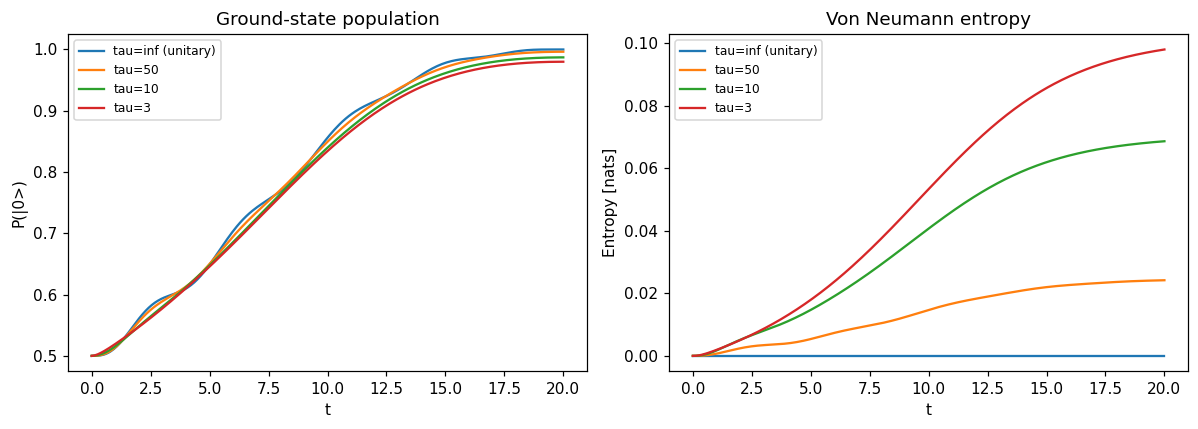

In [4]:
DELTA, BIAS = 1.0, 1.0
H_DRIVER = -DELTA * sigma_x
H_PROBLEM = -BIAS * sigma_z

def make_1q_hamiltonian(t_anneal):
    def H(t):
        s = np.clip(t / t_anneal, 0.0, 1.0)
        return (1 - s) * H_DRIVER + s * H_PROBLEM
    return H

def ground_state(h):
    w, v = np.linalg.eigh(h)
    psi = v[:, np.argmin(w)]
    return np.outer(psi, psi.conj())

def run_1q_seaqt(t_anneal, tau, n_points=300):
    rho0 = ground_state(H_DRIVER)
    H = make_1q_hamiltonian(t_anneal)
    res = evolve(rho0, hamiltonian=H, tau=tau, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    return res.t, p0, ent, res

t_anneal_demo = 20.0
taus_1q = [np.inf, 50.0, 10.0, 3.0]
labels_1q = {np.inf: "tau=inf (unitary)", 50.0: "tau=50", 10.0: "tau=10", 3.0: "tau=3"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
seaqt_1q_trajectories = {}
for tau in taus_1q:
    t, p0, ent, res = run_1q_seaqt(t_anneal_demo, tau)
    seaqt_1q_trajectories[tau] = res
    axes[0].plot(t, p0, label=labels_1q[tau])
    axes[1].plot(t, ent, label=labels_1q[tau])
    print(f"{labels_1q[tau]:>18}: final P(|0>)={p0[-1]:.4f}, final entropy={ent[-1]:.4f}")
axes[0].set_xlabel("t"); axes[0].set_ylabel("P(|0>)"); axes[0].legend(fontsize=8)
axes[0].set_title("Ground-state population")
axes[1].set_xlabel("t"); axes[1].set_ylabel("Entropy [nats]"); axes[1].legend(fontsize=8)
axes[1].set_title("Von Neumann entropy")
fig.tight_layout(); plt.show()

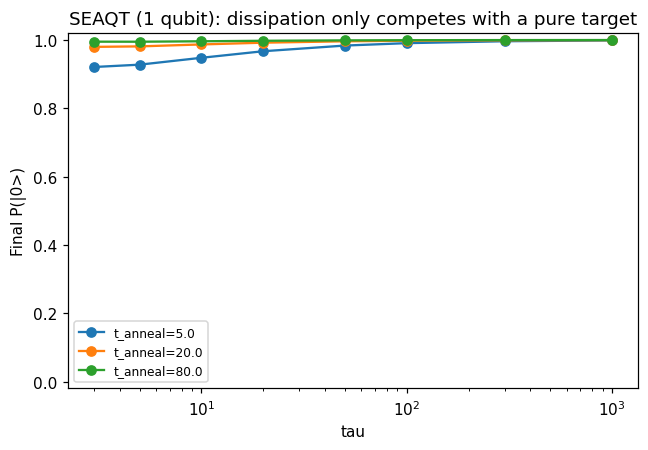

In [5]:
# tau x t_anneal sweep: does slower annealing or stronger dissipation help?
tau_sweep = [3.0, 5.0, 10.0, 20.0, 50.0, 100.0, 300.0, 1000.0]
fig, ax = plt.subplots(figsize=(6, 4.2))
for t_anneal in [5.0, 20.0, 80.0]:
    finals = [run_1q_seaqt(t_anneal, tau, n_points=150)[1][-1] for tau in tau_sweep]
    ax.plot(tau_sweep, finals, marker="o", label=f"t_anneal={t_anneal}")
ax.set_xscale("log"); ax.set_xlabel("tau"); ax.set_ylabel("Final P(|0>)")
ax.set_title("SEAQT (1 qubit): dissipation only competes with a pure target")
ax.legend(fontsize=8); ax.set_ylim(-0.02, 1.02)
fig.tight_layout(); plt.show()

## 3. One qubit -- real D-Wave schedule + bath relaxation

$$H(s) = -\tfrac{A(s)}{2}\sigma_x + \tfrac{B(s)}{2} h_1 \sigma_z$$

with $A(s), B(s)$ read from the QPU datasheet. Note D-Wave's sign
convention: no leading minus on the $B(s)$ term, so the ground state is
$|0\rangle$ for $h_1<0$.

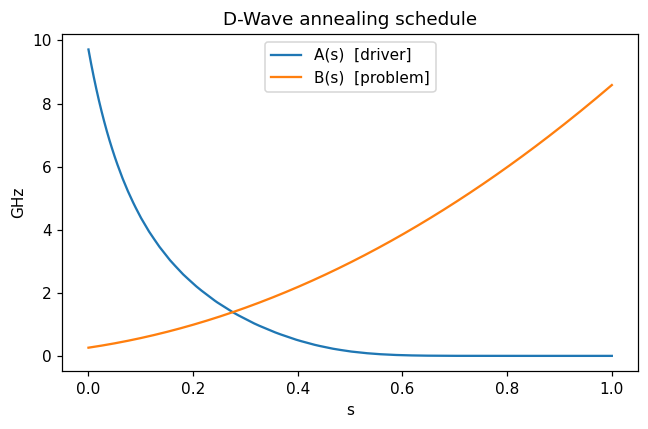

In [6]:
schedule = load_schedule(SCHEDULE_PATH)
s_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s_grid, schedule.A(s_grid), label="A(s)  [driver]")
ax.plot(s_grid, schedule.B(s_grid), label="B(s)  [problem]")
ax.set_xlabel("s"); ax.set_ylabel("GHz"); ax.legend(); ax.set_title("D-Wave annealing schedule")
fig.tight_layout(); plt.show()

beta (15 mK) = 0.5092 ns


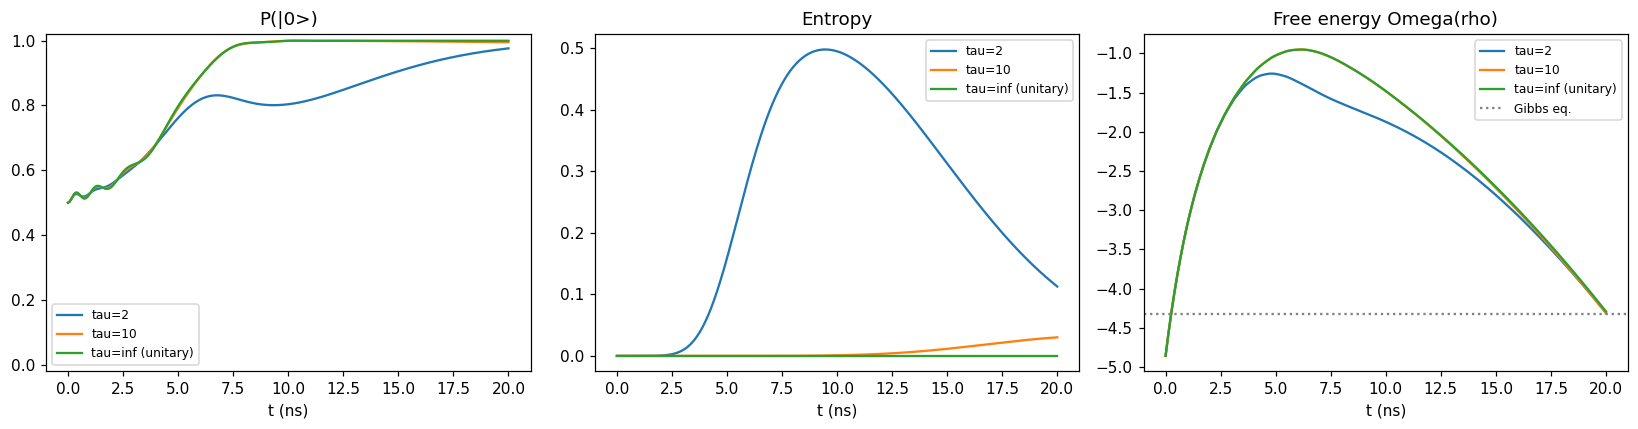

In [7]:
def run_1q_bath(H, t_anneal, tau, beta, n_points=300):
    rho0 = np.array([[0.5, 0.5], [0.5, 0.5]], dtype=complex)  # |+><+|
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p0, ent, omega, res

t_anneal_dw = 20.0
H_dw = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_dw)
beta_bath = beta_from_kelvin(0.015)  # 15 mK
print(f"beta (15 mK) = {beta_bath:.4f} ns")

taus_dw = [2.0, 10.0, np.inf]
labels_dw = {2.0: "tau=2", 10.0: "tau=10", np.inf: "tau=inf (unitary)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bath_1q_trajectories = {}
for tau in taus_dw:
    t, p0, ent, omega, res = run_1q_bath(H_dw, t_anneal_dw, tau, beta_bath)
    bath_1q_trajectories[tau] = res
    axes[0].plot(t, p0, label=labels_dw[tau])
    axes[1].plot(t, ent, label=labels_dw[tau])
    axes[2].plot(t, omega, label=labels_dw[tau])
h_final = H_dw(t_anneal_dw)
omega_eq = free_energy(gibbs_state(h_final, beta_bath), h_final, beta_bath)
axes[2].axhline(omega_eq, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title("P(|0>)"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 4. New: $t_{\text{anneal}} \times \tau$ sweep (D-Wave + bath, 1 qubit)

The open question from the SEAQT case was whether dissipation can ever
*help* rather than hurt. With bath relaxation the target is the Gibbs
state, not a pure state, so the answer can differ across the
($t_{\text{anneal}}$, $\tau$) plane -- let's sweep it directly.

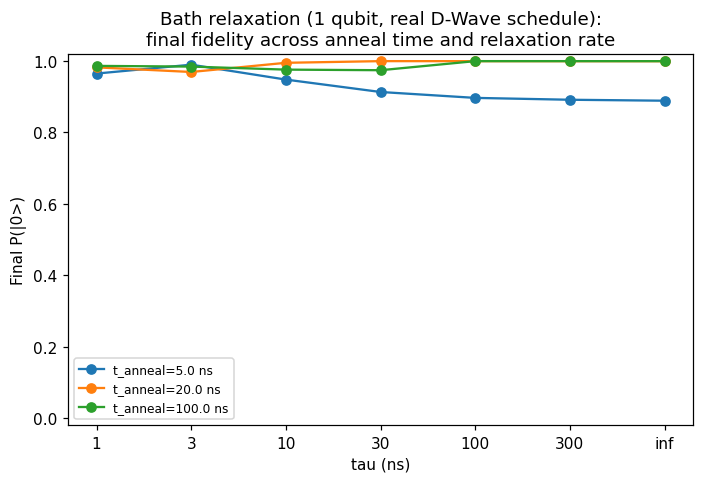

In [8]:
tau_sweep_dw = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, np.inf]
labels_sweep = [f"{t:g}" if np.isfinite(t) else "inf" for t in tau_sweep_dw]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for t_anneal in [5.0, 20.0, 100.0]:
    H_sweep = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal)
    finals = [run_1q_bath(H_sweep, t_anneal, tau, beta_bath, n_points=120)[1][-1] for tau in tau_sweep_dw]
    ax.plot(labels_sweep, finals, marker="o", label=f"t_anneal={t_anneal} ns")
ax.set_xlabel("tau (ns)"); ax.set_ylabel("Final P(|0>)")
ax.set_title("Bath relaxation (1 qubit, real D-Wave schedule):\nfinal fidelity across anneal time and relaxation rate")
ax.legend(fontsize=8); ax.set_ylim(-0.02, 1.02)
fig.tight_layout(); plt.show()

## 5. Bloch sphere trajectories (1 qubit)

Visualizing the same SEAQT and bath trajectories as a path on the Bloch
sphere makes the coherence loss (radial shrinkage) directly visible.

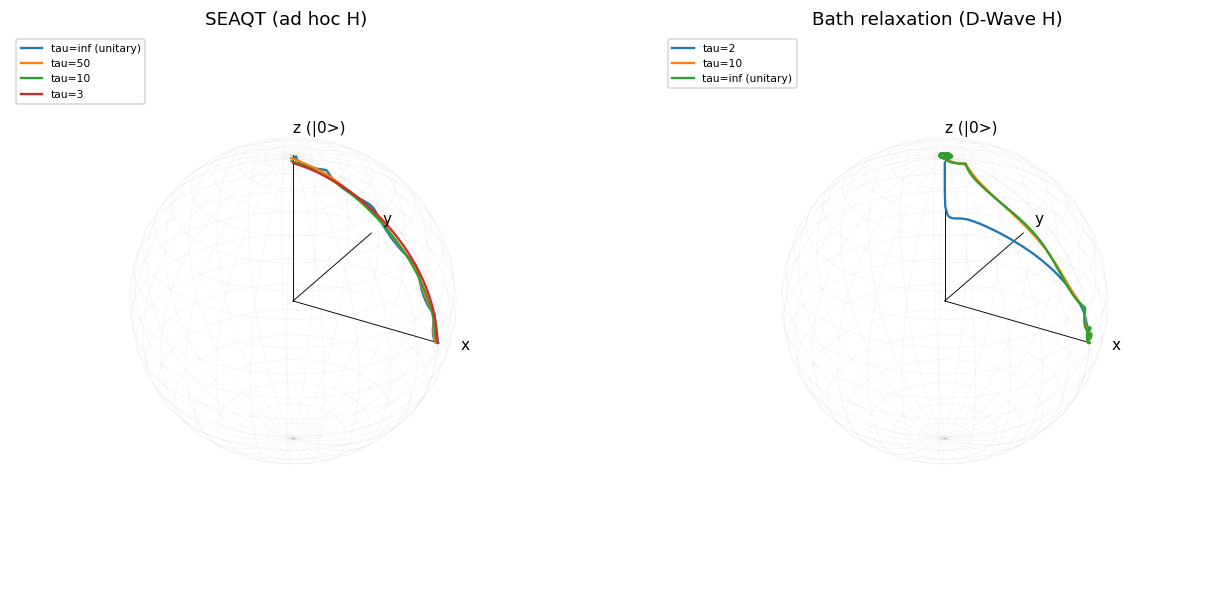

In [9]:
fig = plt.figure(figsize=(12, 5.5))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
draw_bloch_sphere(ax1)
for tau, res in seaqt_1q_trajectories.items():
    xyz = np.array([bloch_vector(r) for r in res.rho])
    ax1.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], label=labels_1q[tau])
ax1.set_title("SEAQT (ad hoc H)"); ax1.legend(fontsize=7, loc="upper left")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
draw_bloch_sphere(ax2)
for tau, res in bath_1q_trajectories.items():
    xyz = np.array([bloch_vector(r) for r in res.rho])
    ax2.plot(xyz[:, 0], xyz[:, 1], xyz[:, 2], label=labels_dw[tau])
ax2.set_title("Bath relaxation (D-Wave H)"); ax2.legend(fontsize=7, loc="upper left")

fig.tight_layout(); plt.show()

## 6. Extending to N qubits

`seaqt.operators` builds Pauli operators on any qubit of an $n$-qubit
register via Kronecker products, and assembles the (D-Wave-convention)
Ising Hamiltonian

$$H = -\tfrac{A}{2}\sum_i \sigma_x^{(i)} + \tfrac{B}{2}\Big(\sum_i h_i \sigma_z^{(i)} + \sum_{i<j} J_{ij}\sigma_z^{(i)}\sigma_z^{(j)}\Big)$$

`sea_dissipator`, `bath_dissipator`, and `evolve` never assumed 2x2 -- they
work unmodified for any Hilbert-space dimension.

In [10]:
H2 = ising_hamiltonian(2, h=[0.6, -0.4], J={(0, 1): 0.5}, A=1.0, B=0.7)
print("2-qubit Hamiltonian, shape", H2.shape, ", Hermitian:", np.allclose(H2, H2.conj().T))
print(H2.real)

# same physics checks as section 1, now on a genuine 4x4 Hamiltonian
rho2 = np.eye(4, dtype=complex) / 4 + 0.05 * (np.random.default_rng(0).normal(size=(4, 4)))
rho2 = hermitize(rho2); rho2 /= np.trace(rho2).real
D2 = sea_dissipator(rho2, H2)
print(f"\n2-qubit SEAQT dissipator: Tr(D)={np.trace(D2):.2e}, Tr(H D)={np.trace(H2@D2):.2e} (both want 0)")

2-qubit Hamiltonian, shape (4, 4) , Hermitian: True
[[ 0.245 -0.5   -0.5    0.   ]
 [-0.5    0.175  0.    -0.5  ]
 [-0.5    0.    -0.525 -0.5  ]
 [ 0.    -0.5   -0.5    0.105]]

2-qubit SEAQT dissipator: Tr(D)=0.00e+00+0.00e+00j, Tr(H D)=2.08e-17+0.00e+00j (both want 0)


## 7. Two qubits -- SEAQT, ad hoc anneal

Same driver $\to$ problem schedule as section 2, extended with a coupling
$J_{12}$. See the gotcha in section 9 for why the initial state is a
slightly-thermalized driver state (`gibbs_state`) rather than the exact
pure ground state, and why the bias $h$ is chosen asymmetric.

Final H eigenvalues: [-0.75  0.15  0.25  0.35]
Ground state: |10>, gap=0.9000


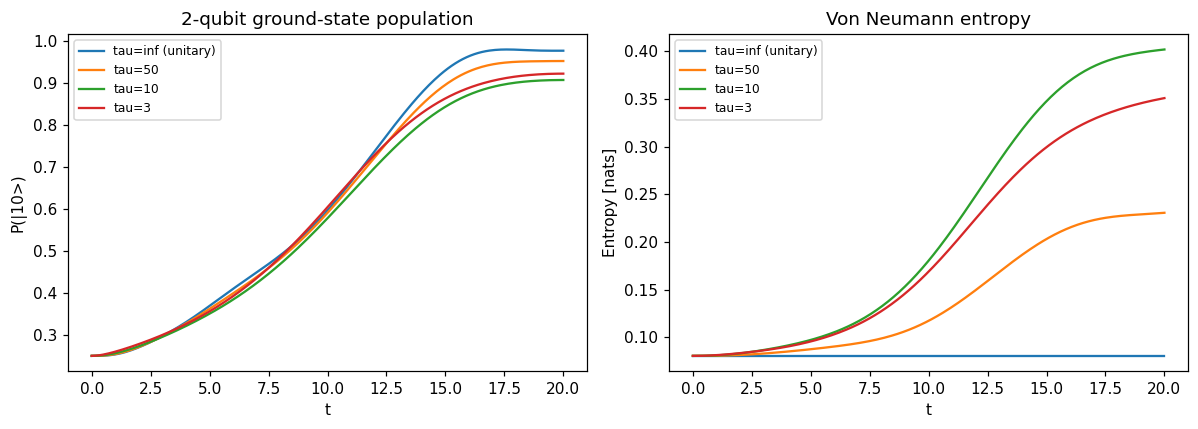

In [11]:
H_BIAS_2Q = [0.6, -0.4]
J12 = 0.5
BETA_INIT = 5.0

def make_2q_hamiltonian(t_anneal):
    def H(t):
        s = np.clip(t / t_anneal, 0.0, 1.0)
        return ising_hamiltonian(2, h=H_BIAS_2Q, J={(0, 1): J12}, A=(1 - s) * 1.0, B=s)
    return H

def run_2q_seaqt(t_anneal, tau, n_points=250):
    H = make_2q_hamiltonian(t_anneal)
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    res = evolve(rho0, hamiltonian=H, tau=tau, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    return res.t, p_ground, ent

H2_final = make_2q_hamiltonian(20.0)(20.0)
w2, v2 = np.linalg.eigh(H2_final)
basis_labels = ["|00>", "|01>", "|10>", "|11>"]
ground_idx_2q = int(np.argmax(np.abs(v2[:, 0])))
print(f"Final H eigenvalues: {w2}")
print(f"Ground state: {basis_labels[ground_idx_2q]}, gap={w2[1]-w2[0]:.4f}")

taus_2q = [np.inf, 50.0, 10.0, 3.0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for tau in taus_2q:
    t, p_ground, ent = run_2q_seaqt(20.0, tau)
    axes[0].plot(t, p_ground, label=labels_1q[tau])
    axes[1].plot(t, ent, label=labels_1q[tau])
axes[0].set_xlabel("t"); axes[0].set_ylabel(f"P({basis_labels[ground_idx_2q]})"); axes[0].legend(fontsize=8)
axes[0].set_title("2-qubit ground-state population")
axes[1].set_xlabel("t"); axes[1].set_ylabel("Entropy [nats]"); axes[1].legend(fontsize=8)
axes[1].set_title("Von Neumann entropy")
fig.tight_layout(); plt.show()

## 8. Two qubits -- D-Wave real schedule + bath relaxation

Ground state: |10>, gap=7.7277


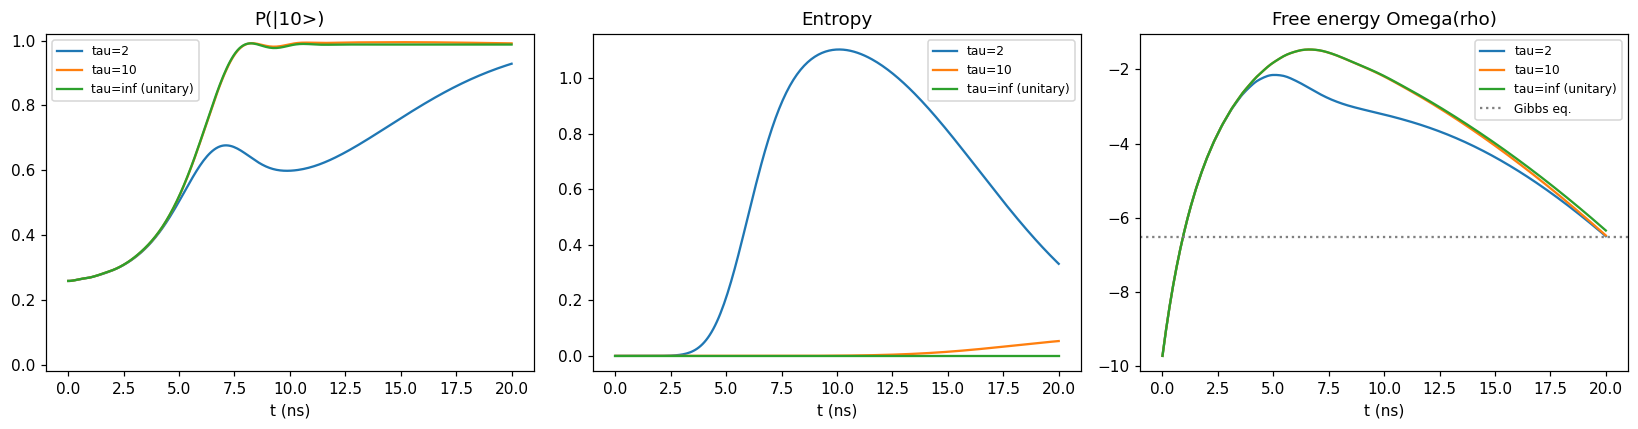

In [12]:
def run_2q_bath(H, t_anneal, tau, beta, n_points=250):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p_ground, ent, omega

t_anneal_2q = 20.0
H_2q_dw = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal_2q)
h2_final = H_2q_dw(t_anneal_2q)
w2dw, v2dw = np.linalg.eigh(h2_final)
ground_idx_2q_dw = int(np.argmax(np.abs(v2dw[:, 0])))
print(f"Ground state: {basis_labels[ground_idx_2q_dw]}, gap={w2dw[1]-w2dw[0]:.4f}")

taus_2q_dw = [2.0, 10.0, np.inf]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for tau in taus_2q_dw:
    t, p_ground, ent, omega = run_2q_bath(H_2q_dw, t_anneal_2q, tau, beta_bath)
    axes[0].plot(t, p_ground, label=labels_dw[tau])
    axes[1].plot(t, ent, label=labels_dw[tau])
    axes[2].plot(t, omega, label=labels_dw[tau])
omega_eq_2q = free_energy(gibbs_state(h2_final, beta_bath), h2_final, beta_bath)
axes[2].axhline(omega_eq_2q, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title(f"P({basis_labels[ground_idx_2q_dw]})"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 9. A numerical gotcha: degenerate eigenvalues in 2+ qubits

Both dissipators compute $\ln\rho$ via `numpy.linalg.eigh` on $\rho$
itself. For a single qubit this is always safe: the "leftover"
(non-dominant) eigenspace of any state is at most 1-dimensional, so there
is never a basis to choose. For 2+ qubits, an **exactly pure** state has a
degenerate zero-eigenvalue eigenspace of dimension $d-1\ge 2$ -- and if
that eigenspace isn't aligned with $H$'s eigenbasis, `eigh` picks an
essentially arbitrary orthonormal basis for it. That choice changes
*discontinuously* under infinitesimal perturbations, which is fatal for
any ODE solver (this is not a hypothetical -- it hung this notebook's
predecessor script for several minutes before being tracked down).

We reproduce the discontinuity here directly (cheap, instantaneous -- no
ODE integration), then show the fix (thermalized initial state) removes
it.

In [13]:
# H0 has a driver with a doubly-degenerate zero-energy eigenspace (2 qubits, no coupling)
H0_pathological = ising_hamiltonian(2, h=[0, 0], J=None, A=1.0, B=0.0)
w0, v0 = np.linalg.eigh(H0_pathological)
psi0 = v0[:, np.argmin(w0)]
rho0_pure = np.outer(psi0, psi0.conj())  # EXACT pure ground state -- the pathological case

rng = np.random.default_rng(0)
print("Pure initial state: tiny perturbations cause LARGE, discontinuous jumps in D")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho0_pure + eps * perturb
    rho = rho / np.trace(rho).real
    D = sea_dissipator(rho, H0_pathological)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.4f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.4f}{change}")
    prev_D = D

Pure initial state: tiny perturbations cause LARGE, discontinuous jumps in D
  eps=0e+00: ||D||_max = 6.9078
  eps=1e-09: ||D||_max = 7.1749, ||delta D|| = 2.3703
  eps=1e-08: ||D||_max = 6.1431, ||delta D|| = 4.6154
  eps=1e-06: ||D||_max = 3.2060, ||delta D|| = 5.6759


In [14]:
# Fix: initialize from a slightly-thermalized driver state (commutes with H0
# exactly, so there's no ambiguous eigenbasis to pick) instead of the exact
# pure ground state.
rho0_thermal = gibbs_state(H0_pathological, beta=5.0)
print("Thermalized initial state: D stays smooth (near-zero) under the same perturbations")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho0_thermal + eps * perturb
    rho = rho / np.trace(rho).real
    D = sea_dissipator(rho, H0_pathological)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.4f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.4f}{change}")
    prev_D = D

print("\nThis -- plus picking problem instances with a comfortable minimum gap "
      "(no exact/near-exact degeneracies anywhere along the schedule) -- is why "
      "sections 7-8 above use gibbs_state(...) for rho0 and an asymmetric h.")

Thermalized initial state: D stays smooth (near-zero) under the same perturbations
  eps=0e+00: ||D||_max = 0.0000
  eps=1e-09: ||D||_max = 0.0000, ||delta D|| = 0.0000
  eps=1e-08: ||D||_max = 0.0000, ||delta D|| = 0.0000
  eps=1e-06: ||D||_max = 0.0019, ||delta D|| = 0.0019

This -- plus picking problem instances with a comfortable minimum gap (no exact/near-exact degeneracies anywhere along the schedule) -- is why sections 7-8 above use gibbs_state(...) for rho0 and an asymmetric h.


## Next steps

- Explore an intentionally (near-)degenerate multi-qubit ground-state
  manifold with a stiff-aware integration strategy (analytic Jacobian, a
  proper implicit solver, or a regularized dissipator) robust enough to
  handle the small-minimum-gap regime demonstrated in section 9.
- Push past 2 qubits -- everything here already works for any finite
  Hilbert-space dimension $d=2^n$; going further is a runtime/tooling
  question, not a physics one.
- Explore state- or schedule-dependent $\tau(\rho, t)$ rather than a
  constant relaxation time.
- Compare against real D-Wave hardware results for a small problem
  instance, once available.